# Benchmark: mboostrs and six other libraries

This benchmark compares eight configurations of seven libraries on held-out data
from six tabular datasets: seven tuned configurations and a fixed pretrained
NVIDIA Kumo Tabular baseline. The following choices determine what the scores
compare.

*Every model sees the same splits.* Evaluation is three random 75/25 splits per
dataset with seeds shared across libraries, so no model is scored on an easier
partition than another.

*Tuning budgets.* Under equal search effort every
library draws the same number of hyperparameter configurations and is scored by
the same inner cross-validation. That ignores the fact that one library fits in
0.02 seconds and another in 18. Under equal wall-clock every library gets the
same tuning time and draws configurations until it runs out, which lets a fast
library search further. Both protocols are run below for the seven tuned configurations. Kumo is
evaluated once per split with a fixed configuration, without inner CV or search;
its results are added in the Kumo comparison below.

*Two of the tuned configurations cannot fit interactions.* mboostrs `GAMBoost` fits a sum of
one-dimensional P-splines. A depth-1 XGBoost fits a sum of stumps, which is also
a sum of one-dimensional terms, and it is here as a control: it holds the
function class fixed while changing the library, so the additive-to-unrestricted
gap can be read separately from the mboostrs-to-XGBoost gap.

Preprocessing is identical everywhere: median imputation, one-hot encoding, and
standardisation applied only to the MLP, which needs it. Every model's predictions
are held to the range of the responses in its own training split before scoring,
because a spline surface or a neural network can extrapolate far outside that range
and a squared-error metric punishes this out of proportion to the rows involved.

This benchmark assumes the fitting workflow is already familiar. It teaches how the
comparison holds data, folds, search effort and scoring boundaries fixed before reading
accuracy or timing differences.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how mboostrs scores against six other libraries on held-out data |
| **Observed response** | the target column of each of six tabular datasets |
| **Estimand** | held-out predictive score with shared sample cap, metric and splits; tuning budgets matched within the tuned-model comparison |
| **Units** | the metric's own units per dataset |
| **Sampling unit** | one row of each dataset |
| **Dependence** | treated as independent within each dataset |
| **Split / resampling unit** | the row, with the same split given to every library |
| **Tuning** | equal budgets for the tuned models; one prespecified configuration for pretrained Kumo |
| **Uncertainty** | across-split variation reported alongside the point estimates |
| **Claim type** | predictive comparison under stated conditions. A speed or score ratio here is not a statement about estimator quality in general |
:::


In [1]:
import json
from pathlib import Path

import numpy as np
import polars as pl
import altair as alt

bench = json.loads(Path("bench_libraries.json").read_text())
protocol = bench["protocol"]
runs = pl.DataFrame(bench["results"])

ORDER = ["mboostrs GAMBoost", "EBM", "XGBoost depth 1", "XGBoost",
         "LightGBM", "CatBoost", "MLP"]
COLOUR = {"mboostrs GAMBoost": "#4e79a7", "EBM": "#59a14f", "XGBoost depth 1": "#9c755f",
          "XGBoost": "#e15759", "LightGBM": "#edc948", "CatBoost": "#b07aa1",
          "MLP": "#76b7b2"}
scale = alt.Scale(domain=ORDER, range=[COLOUR[k] for k in ORDER])

print(f"{protocol['repeats']} splits per dataset, "
      f"{protocol['n_configs']} configurations under the equal-effort protocol, "
      f"{protocol['inner_folds']}-fold inner CV,\n"
      f"{protocol['time_budget_s']:.0f}s tuning budget under the equal-time protocol, "
      f"datasets capped at {protocol['max_rows']} rows.")
print(f"{runs.height} runs: {runs['library'].n_unique()} libraries x "
      f"{runs['dataset'].n_unique()} datasets x {protocol['repeats']} splits x 2 protocols")

3 splits per dataset, 12 configurations under the equal-effort protocol, 3-fold inner CV,
15s tuning budget under the equal-time protocol, datasets capped at 5000 rows.
252 runs: 7 libraries x 6 datasets x 3 splits x 2 protocols


## Results for the seven tuned configurations

The table gives each tuned configuration's held-out score on each dataset,
its mean rank, and the seconds it took to tune and refit. These are the original
recorded results. The next section adds Kumo and recomputes ranks across all
eight configurations.

In [2]:
SCORE_NOTE = ("Scores are the mean over three random 75/25 splits shared by every library: "
              "test R² for california, cpu_act and diabetes, test ROC AUC for breast_cancer, "
              "credit_g and electricity; both are higher-is-better with 1 the maximum.")

from bench_tables import table as annotated


def by_dataset(mode):
    return (runs.filter(pl.col("mode") == mode)
            .group_by("dataset", "library").agg(pl.col("score").mean())
            .pivot(on="dataset", index="library", values="score"))


DATASETS = ["california", "cpu_act", "diabetes", "breast_cancer", "credit_g", "electricity"]
ranks = (runs.filter(pl.col("mode") == "configs")
         .group_by("dataset", "library").agg(pl.col("score").mean())
         .with_columns((-pl.col("score")).rank("average").over("dataset").alias("rank"))
         .group_by("library").agg(pl.col("rank").mean().alias("rank")))
seconds = (runs.filter(pl.col("mode") == "configs").group_by("library")
           .agg(pl.col("total_seconds").mean().alias("seconds")))

In [3]:
annotated(
    by_dataset("configs").join(ranks, on="library").join(seconds, on="library")
    .select("library", *DATASETS, "rank", "seconds").sort("rank"),
    stub="library", stubhead="Library",
    title="Seven configurations of six libraries on six data sets",
    subtitle="Held-out score, mean over 3 random 75/25 splits; 12 configurations per library",
    spanners={"R² ↑": DATASETS[:3], "AUC ↑": DATASETS[3:]},
    labels={"rank": "mean rank ↓", "seconds": "s ↓"},
    better={**{d: "max" for d in DATASETS}, "rank": "min", "seconds": "min"},
    formats={"rank": 2, "seconds": 1}, decimals=3,
    notes=[SCORE_NOTE, "mean rank: rank of the library on each data set (1 is best), "
           "averaged over the six. s: mean seconds to tune (12 configurations, 3-fold CV) "
           "and refit. Bold: best in the column. Differences in the third decimal are "
           "within the variation between splits. Source: bench_libraries.json, written by "
           "benches/bench_libraries.py."])

GT(_tbl_data=shape: (7, 9)
┌────────────┬────────────┬──────────┬──────────┬───┬──────────┬────────────┬──────────┬───────────┐
│ library    ┆ california ┆ cpu_act  ┆ diabetes ┆ … ┆ credit_g ┆ electricit ┆ rank     ┆ seconds   │
│ ---        ┆ ---        ┆ ---      ┆ ---      ┆   ┆ ---      ┆ y          ┆ ---      ┆ ---       │
│ str        ┆ f64        ┆ f64      ┆ f64      ┆   ┆ f64      ┆ ---        ┆ f64      ┆ f64       │
│            ┆            ┆          ┆          ┆   ┆          ┆ f64        ┆          ┆           │
╞════════════╪════════════╪══════════╪══════════╪═══╪══════════╪════════════╪══════════╪═══════════╡
│ CatBoost   ┆ 0.827827   ┆ 0.984909 ┆ 0.447118 ┆ … ┆ 0.793194 ┆ 0.918455   ┆ 2.333333 ┆ 14.808889 │
│ EBM        ┆ 0.80842    ┆ 0.984704 ┆ 0.484613 ┆ … ┆ 0.795479 ┆ 0.908458   ┆ 2.5      ┆ 105.15444 │
│            ┆            ┆          ┆          ┆   ┆          ┆            ┆          ┆ 4         │
│ LightGBM   ┆ 0.814093   ┆ 0.982822 ┆ 0.417331 ┆ … ┆ 0.786794 ┆ 0.918378   ┆ 3.5      ┆ 37.095    │
│ XGBoost    ┆ 0.813615   ┆ 0.985283 ┆ 0.411659 ┆ … ┆ 0.788978 ┆ 0.917252   ┆ 3.666667 ┆ 19.602778 │
│ mboostrs   ┆ 0.718742   ┆ 0.980789 ┆ 0.499496 ┆ … ┆ 0.789257 ┆ 0.85954    ┆ 4.666667 ┆ 1.002778  │
│ GAMBoost   ┆            ┆          ┆          ┆   ┆          ┆            ┆          ┆           │
│ XGBoost    ┆ 0.751722   ┆ 0.982491 ┆ 0.465268 ┆ … ┆ 0.781752 ┆ 0.881936   ┆ 5.0      ┆ 8.649444  │
│ depth 1    ┆            ┆          ┆          ┆   ┆          ┆            ┆          ┆           │
│ MLP        ┆ 0.732678   ┆ 0.97563  ┆ 0.452435 ┆ … ┆ 0.767213 ┆ 0.853349   ┆ 6.333333 ┆ 6.337778  │
└────────────┴────────────┴──────────┴──────────┴───┴──────────┴────────────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10e1f4860>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='california', type=<ColInfoTypeEnum.default: 1>, column_label='california', column_align='right', column_width=None), ColInfo(var='cpu_act', type=<ColInfoTypeEnum.default: 1>, column_label='cpu_act', column_align='right', column_width=None), ColInfo(var='diabetes', type=<ColInfoTypeEnum.default: 1>, column_label='diabetes', column_align='right', column_width=None), ColInfo(var='breast_cancer', type=<ColInfoTypeEnum.default: 1>, column_label='breast_cancer', column_align='right', column_width=None), ColInfo(var='credit_g', type=<ColInfoTypeEnum.default: 1>, column_label='credit_g', column_align='right', column_width=None), ColInfo(var='electricity', type=<ColInfoTypeEnum.default: 1>, column_label='electricity', column_align='right', column_width=None), ColInfo(var='rank', type=<ColInfoTypeEnum.default: 1>, column_label='mean rank ↓', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s ↓', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e40b260>, _spanners=Spanners([SpannerInfo(spanner_id='R² ↑', spanner_level=0, spanner_label='R² ↑', spanner_units=None, spanner_pattern=None, vars=['california', 'cpu_act', 'diabetes'], built=None), SpannerInfo(spanner_id='AUC ↑', spanner_level=0, spanner_label='AUC ↑', spanner_units=None, spanner_pattern=None, vars=['breast_cancer', 'credit_g', 'electricity'], built=None)]), _heading=Heading(title='Seven configurations of six libraries on six data sets', subtitle='Held-out score, mean over 3 random 75/25 splits; 12 configurations per library', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f48d490>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10e224f50>, _source_notes=['Scores are the mean over three random 75/25 splits shared by every library: test R² for california, cpu_act and diabetes, test ROC AUC for breast_cancer, credit_g and electricity; both are higher-is-better with 1 the maximum.', 'mean

## Adding NVIDIA Kumo Tabular

[NVIDIA Kumo Tabular](https://docs.nvidia.com/sdgm/structured-data-models/models/kumo-tabular)
is a pretrained model for single-table regression and classification. This study
uses the **small** model from `structured-data-models==0.2.1`, weights revision
`v1.0.1`, eight ensemble estimators and a seeded CPU generator. Small is an
explicit CPU baseline; it is not the library's default large model.

Kumo receives all training rows as labeled context and only the predictors of
held-out rows as queries. It uses the original dataset subsampling, three 75/25
splits and training-only median imputation / one-hot encoding. Its internal
pretrained recipe runs in addition to this shared encoding. There is no
fine-tuning, configuration search or use of test labels during prediction.
Classification uses the probability column named for the positive class.
For regression, the mean of its 999 equally spaced predictive quantiles
approximates the predictive expectation for R² scoring, followed by the same
training-response clipping rule as the other models.

The table combines the original tuned-model measurements with this later Kumo
run on the same data and split seeds. It compares predictive scores, **not equal
training effort or total pretraining compute**. Kumo's upstream pretraining is
outside this experiment. The original seven-model analyses below retain their
original scope; the eight-model ranks here are recomputed separately.

Reproduce the Kumo measurements with Python 3.11 or later:

```bash
pip install structured-data-models==0.2.1 pandas scikit-learn
python benches/bench_libraries_kumo.py --cache-dir /tmp/kumo-library-jobs
```

The runner records package versions, input hashes, thread counts and per-row
measurement identities, and reports failed splits explicitly. The original
comparison is reproduced with `benches/bench_libraries.py`.


In [4]:
# Kumo is a fixed pretrained baseline, so it is ranked against the other libraries
# only on the same datasets and splits; the asserts below fail if they differ.
kumo_bench = json.loads(Path("bench_libraries_kumo.json").read_text())
expected = {(d, r) for d in DATASETS for r in range(protocol["repeats"])}
assert {(r["dataset"], r["repeat"]) for r in kumo_bench["results"]} == expected
assert len(kumo_bench["results"]) == len(expected)
assert all(r["_status"] == "success" for r in kumo_bench["results"])
assert all(kumo_bench["protocol"][k] == protocol[k]
           for k in ("seed", "max_rows", "repeats"))
kumo = pl.DataFrame([{k: r[k] for k in (
    "dataset", "repeat", "library", "score", "load_seconds", "total_seconds")}
    for r in kumo_bench["results"]])
combined = pl.concat([
    runs.filter(pl.col("mode") == "configs").select("dataset", "repeat", "library", "score"),
    kumo.select("dataset", "repeat", "library", "score"),
])
means = combined.group_by("dataset", "library").agg(pl.col("score").mean())
all_ranks = (means.with_columns(
    (-pl.col("score")).rank("average").over("dataset").alias("rank"))
    .group_by("library").agg(pl.col("rank").mean()))
annotated(
    means.pivot(on="dataset", index="library", values="score")
    .join(all_ranks, on="library").select("library", *DATASETS, "rank").sort("rank"),
    stub="library", stubhead="Configuration",
    title="Eight configurations of seven libraries, including NVIDIA Kumo",
    subtitle="Mean held-out score over the same three splits; tuned models plus fixed pretrained baseline",
    spanners={"R² ↑": DATASETS[:3], "AUC ↑": DATASETS[3:]},
    labels={"rank": "mean rank ↓"}, formats={"rank": 2}, decimals=3,
    better={**{d: "max" for d in DATASETS}, "rank": "min"},
    notes=[SCORE_NOTE,
           "Kumo: small, eight estimators, no tuning. Other configurations: 12-config search with 3-fold CV.",
           "Measurement dates: original models " + bench["provenance"]["created_at"][:10]
           + "; Kumo " + kumo_bench["provenance"]["created_at"][:10] + ". "
           "Sources: bench_libraries.json and bench_libraries_kumo.json."])


GT(_tbl_data=shape: (8, 8)
┌─────────────┬────────────┬──────────┬──────────┬─────────────┬──────────┬─────────────┬──────────┐
│ library     ┆ california ┆ cpu_act  ┆ diabetes ┆ breast_canc ┆ credit_g ┆ electricity ┆ rank     │
│ ---         ┆ ---        ┆ ---      ┆ ---      ┆ er          ┆ ---      ┆ ---         ┆ ---      │
│ str         ┆ f64        ┆ f64      ┆ f64      ┆ ---         ┆ f64      ┆ f64         ┆ f64      │
│             ┆            ┆          ┆          ┆ f64         ┆          ┆             ┆          │
╞═════════════╪════════════╪══════════╪══════════╪═════════════╪══════════╪═════════════╪══════════╡
│ NVIDIA Kumo ┆ 0.870903   ┆ 0.988555 ┆ 0.502457 ┆ 0.997973    ┆ 0.795429 ┆ 0.939833    ┆ 1.416667 │
│ Tabular     ┆            ┆          ┆          ┆             ┆          ┆             ┆          │
│ (small)     ┆            ┆          ┆          ┆             ┆          ┆             ┆          │
│ EBM         ┆ 0.80842    ┆ 0.984704 ┆ 0.484613 ┆ 0.998463    ┆ 0.795479 ┆ 0.908458    ┆ 3.166667 │
│ CatBoost    ┆ 0.827827   ┆ 0.984909 ┆ 0.447118 ┆ 0.996995    ┆ 0.793194 ┆ 0.918455    ┆ 3.333333 │
│ LightGBM    ┆ 0.814093   ┆ 0.982822 ┆ 0.417331 ┆ 0.997973    ┆ 0.786794 ┆ 0.918378    ┆ 4.416667 │
│ XGBoost     ┆ 0.813615   ┆ 0.985283 ┆ 0.411659 ┆ 0.995388    ┆ 0.788978 ┆ 0.917252    ┆ 4.666667 │
│ mboostrs    ┆ 0.718742   ┆ 0.980789 ┆ 0.499496 ┆ 0.995318    ┆ 0.789257 ┆ 0.85954     ┆ 5.666667 │
│ GAMBoost    ┆            ┆          ┆          ┆             ┆          ┆             ┆          │
│ XGBoost     ┆ 0.751722   ┆ 0.982491 ┆ 0.465268 ┆ 0.994549    ┆ 0.781752 ┆ 0.881936    ┆ 6.0      │
│ depth 1     ┆            ┆          ┆          ┆             ┆          ┆             ┆          │
│ MLP         ┆ 0.732678   ┆ 0.97563  ┆ 0.452435 ┆ 0.991754    ┆ 0.767213 ┆ 0.853349    ┆ 7.333333 │
└─────────────┴────────────┴──────────┴──────────┴─────────────┴──────────┴─────────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10c32efd0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None, stub_level=0), ColInfo(var='california', type=<ColInfoTypeEnum.default: 1>, column_label='california', column_align='right', column_width=None, stub_level=None), ColInfo(var='cpu_act', type=<ColInfoTypeEnum.default: 1>, column_label='cpu_act', column_align='right', column_width=None, stub_level=None), ColInfo(var='diabetes', type=<ColInfoTypeEnum.default: 1>, column_label='diabetes', column_align='right', column_width=None, stub_level=None), ColInfo(var='breast_cancer', type=<ColInfoTypeEnum.default: 1>, column_label='breast_cancer', column_align='right', column_width=None, stub_level=None), ColInfo(var='credit_g', type=<ColInfoTypeEnum.default: 1>, column_label='credit_g', column_align='right', column_width=None, stub_level=None), ColInfo(var='electricity', type=<ColInfoTypeEnum.default: 1>, column_label='electricity', column_align='right', column_width=None, stub_level=None), ColInfo(var='rank', type=<ColInfoTypeEnum.default: 1>, column_label='mean rank ↓', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b631450>, _spanners=Spanners([SpannerInfo(spanner_id='R² ↑', spanner_level=0, spanner_label='R² ↑', spanner_units=None, spanner_pattern=None, vars=['california', 'cpu_act', 'diabetes'], built=None), SpannerInfo(spanner_id='AUC ↑', spanner_level=0, spanner_label='AUC ↑', spanner_units=None, spanner_pattern=None, vars=['breast_cancer', 'credit_g', 'electricity'], built=None)]), _heading=Heading(title='Eight configurations of seven libraries, including NVIDIA Kumo', subtitle='Mean held-out score over the same three splits; tuned models plus fixed pretrained baseline', preheader=None), _stubhead='Configuration', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c3b6490>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10c32eb10>, _source

In [5]:
annotated(
    kumo.group_by("dataset").agg(
        pl.col("score").mean().alias("mean score"),
        pl.col("score").std(ddof=1).alias("split SD"),
        pl.col("total_seconds").mean().alias("inference s"),
        pl.col("load_seconds").mean().alias("load s")),
    stub="dataset", stubhead="Dataset", title="Kumo accuracy, variation and elapsed time",
    subtitle="Small model, eight estimators, CPU with one PyTorch thread; mean over three splits",
    formats={"inference s": 2, "load s": 2}, decimals=4,
    notes=["Split SD: sample standard deviation of the three held-out scores, not a confidence interval.",
           "Inference includes training-only encoding, table conversion, forward pass and scoring. "
           "Loading weights is separate and includes the first download when needed. No warmup.",
           "The existing tune/refit timings were measured separately with different software versions; "
           "these measurements do not support a cross-library speed ratio."])


GT(_tbl_data=shape: (6, 5)
┌───────────────┬────────────┬──────────┬─────────────┬──────────┐
│ dataset       ┆ mean score ┆ split SD ┆ inference s ┆ load s   │
│ ---           ┆ ---        ┆ ---      ┆ ---         ┆ ---      │
│ str           ┆ f64        ┆ f64      ┆ f64         ┆ f64      │
╞═══════════════╪════════════╪══════════╪═════════════╪══════════╡
│ diabetes      ┆ 0.502457   ┆ 0.074718 ┆ 1.050446    ┆ 0.366752 │
│ california    ┆ 0.870903   ┆ 0.00869  ┆ 21.584516   ┆ 0.337214 │
│ breast_cancer ┆ 0.997973   ┆ 0.001396 ┆ 2.955592    ┆ 6.399125 │
│ cpu_act       ┆ 0.988555   ┆ 0.000472 ┆ 30.626678   ┆ 0.379308 │
│ credit_g      ┆ 0.795429   ┆ 0.003527 ┆ 9.228261    ┆ 0.34076  │
│ electricity   ┆ 0.939833   ┆ 0.008907 ┆ 25.783613   ┆ 0.341469 │
└───────────────┴────────────┴──────────┴─────────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10c342cf0>, _boxhead=Boxhead([ColInfo(var='dataset', type=<ColInfoTypeEnum.stub: 2>, column_label='dataset', column_align='left', column_width=None, stub_level=0), ColInfo(var='mean score', type=<ColInfoTypeEnum.default: 1>, column_label='mean score', column_align='right', column_width=None, stub_level=None), ColInfo(var='split SD', type=<ColInfoTypeEnum.default: 1>, column_label='split SD', column_align='right', column_width=None, stub_level=None), ColInfo(var='inference s', type=<ColInfoTypeEnum.default: 1>, column_label='inference s', column_align='right', column_width=None, stub_level=None), ColInfo(var='load s', type=<ColInfoTypeEnum.default: 1>, column_label='load s', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c3b4910>, _spanners=Spanners([]), _heading=Heading(title='Kumo accuracy, variation and elapsed time', subtitle='Small model, eight estimators, CPU with one PyTorch thread; mean over three splits', preheader=None), _stubhead='Dataset', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c32fa80>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10c332d50>, _source_notes=['Split SD: sample standard deviation of the three held-out scores, not a confidence interval.', 'Inference includes training-only encoding, table conversion, forward pass and scoring. Loading weights is separate and includes the first download when needed. No warmup.', 'The existing tune/refit timings were measured separately with different software versions; these measurements do not support a cross-library speed ratio.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10c3b5950>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c37dc80>, <great_tables._gt_data.FormatInfo object at 0x10c37dd30>, <great_tables._gt_data.FormatInfo object at 0x10c40ce10>, <great_tables._gt_data.FormatInfo object at 0x10c40cff0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10c36acc0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=Tr

In [6]:
all_order = ORDER + ["NVIDIA Kumo Tabular (small)"]
all_scale = alt.Scale(domain=all_order,
                      range=[COLOUR[k] for k in ORDER] + ["#f28e2b"])
alt.Chart(means).mark_bar().encode(
    y=alt.Y("library:N", sort=all_order, title=None),
    x=alt.X("score:Q", title="held-out score (R² or AUC)", scale=alt.Scale(zero=False)),
    color=alt.Color("library:N", scale=all_scale, legend=None),
    tooltip=["library", "dataset", alt.Tooltip("score:Q", format=".4f")],
).properties(width=170, height=160).facet(
    facet=alt.Facet("dataset:N", title=None), columns=3, spacing=14,
).resolve_scale(x="independent").properties(
    title="Held-out accuracy including the fixed NVIDIA Kumo baseline")


alt.FacetChart(...)

Kumo small has the highest mean score on four of the six datasets and a mean
rank of 1.33 across the eight configurations. Its California R² is 0.871,
compared with 0.828 for the best tuned model in the original run. On diabetes,
its 0.502 is close to mboostrs at 0.499, while Kumo's across-split standard
deviation is 0.075: that ordering is not evidence of a resolved difference.
EBM remains ahead on breast_cancer and credit_g, with very small mean-score
gaps. These results describe this small pretrained configuration and these
splits; they do not establish a general ordering of libraries.

### Public datasets and possible benchmark contamination

NVIDIA reports that Kumo Tabular was pretrained entirely on procedurally
generated synthetic tables, rather than real datasets
([training description](https://huggingface.co/blog/nvidia/kumo-tabular#how-kumo-tabular-was-built)).
If that disclosure is complete, direct memorization of these datasets' actual
rows and labels during pretraining is unlikely. This study has not independently
audited the training data and cannot assign a probability to contamination.

Synthetic-only pretraining does not rule out benchmark-driven development:
architectures, synthetic generators, recipes or checkpoints could have been
selected using results on familiar public datasets. This study does not establish
whether that happened. Shared random held-out splits prevent test-label leakage
through the context supplied in this experiment; they do not establish that the
datasets were unseen during model development.

The results therefore describe performance on these six public datasets, rather
than proven generalization to previously unseen tasks. A stronger follow-up would
fix the evaluation protocol before testing on fresh private synthetic tasks with
known additive and interaction structures, and on real datasets unavailable during
model development. Shuffled-context-label controls can help diagnose reliance on
the supplied labels, but cannot certify the absence of contamination.

## The datasets

Six tabular sets, three regression and three classification, drawn from
scikit-learn and OpenML. Anything larger than 5000 rows is subsampled to 5000
with a fixed seed, so that the slowest library in the comparison can be tuned on
the same terms as the fastest.

In [4]:
annotated(
    runs.select("dataset", "task", "n", "p").unique().sort("task", "n", descending=[False, True]),
    stub="dataset", stubhead="Data set",
    title="The six data sets", subtitle="Rows after the 5,000-row cap, and predictors",
    labels={"n": "rows", "p": "predictors"},
    notes=["Regression data sets are scored by test R², classification by test ROC AUC. "
           "credit_g has 53 one-hot indicator columns among its 59."])

GT(_tbl_data=shape: (6, 4)
┌───────────────┬────────────────┬──────┬─────┐
│ dataset       ┆ task           ┆ n    ┆ p   │
│ ---           ┆ ---            ┆ ---  ┆ --- │
│ str           ┆ str            ┆ i64  ┆ i64 │
╞═══════════════╪════════════════╪══════╪═════╡
│ electricity   ┆ classification ┆ 5000 ┆ 8   │
│ credit_g      ┆ classification ┆ 1000 ┆ 20  │
│ breast_cancer ┆ classification ┆ 569  ┆ 30  │
│ california    ┆ regression     ┆ 5000 ┆ 8   │
│ cpu_act       ┆ regression     ┆ 5000 ┆ 21  │
│ diabetes      ┆ regression     ┆ 442  ┆ 10  │
└───────────────┴────────────────┴──────┴─────┘, _body=<great_tables._gt_data.Body object at 0x10e794a40>, _boxhead=Boxhead([ColInfo(var='dataset', type=<ColInfoTypeEnum.stub: 2>, column_label='dataset', column_align='left', column_width=None), ColInfo(var='task', type=<ColInfoTypeEnum.default: 1>, column_label='task', column_align='left', column_width=None), ColInfo(var='n', type=<ColInfoTypeEnum.default: 1>, column_label='rows', column_align='right', column_width=None), ColInfo(var='p', type=<ColInfoTypeEnum.default: 1>, column_label='predictors', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e40ba40>, _spanners=Spanners([]), _heading=Heading(title='The six data sets', subtitle='Rows after the 5,000-row cap, and predictors', preheader=None), _stubhead='Data set', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fd5c890>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd5c7a0>, _source_notes=['Regression data sets are scored by test R², classification by test ROC AUC. credit_g has 53 one-hot indicator columns among its 59.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10fd5c7d0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fd5c680>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='t

## Function classes of the seven tuned configurations

Two of the seven are additive by construction: the fitted function is a sum of
one-dimensional terms and no interaction between predictors can be represented.
`mboostrs` `GAMBoost` fits a P-spline per predictor by component-wise boosting.
An XGBoost restricted to depth-1 trees fits a sum of stumps, which is also
additive, and it is in the comparison as a control — it holds the function class
fixed while changing the library, so the additive-to-interaction gap can be read
separately from the mboostrs-to-XGBoost gap.

EBM is additive in its base terms and adds a bounded number of pairwise
interactions, tuned here between none and ten. The remaining four fit
unrestricted interactions.

In [5]:
annotated(
    runs.select("library", "family").unique()
    .with_columns(pl.col("library").replace_strict({k: i for i, k in enumerate(ORDER)}).alias("o"))
    .sort("o").drop("o"),
    stub="library", stubhead="Library",
    title="Function class of each configuration", subtitle="What each model can represent",
    notes=["additive: a sum of one-dimensional terms, no interaction between predictors."])

GT(_tbl_data=shape: (7, 2)
┌───────────────────┬──────────────────┐
│ library           ┆ family           │
│ ---               ┆ ---              │
│ str               ┆ str              │
╞═══════════════════╪══════════════════╡
│ mboostrs GAMBoost ┆ additive         │
│ EBM               ┆ additive + pairs │
│ XGBoost depth 1   ┆ additive         │
│ XGBoost           ┆ interactions     │
│ LightGBM          ┆ interactions     │
│ CatBoost          ┆ interactions     │
│ MLP               ┆ interactions     │
└───────────────────┴──────────────────┘, _body=<great_tables._gt_data.Body object at 0x10fd13a10>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='family', type=<ColInfoTypeEnum.default: 1>, column_label='family', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ddcad20>, _spanners=Spanners([]), _heading=Heading(title='Function class of each configuration', subtitle='What each model can represent', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fd5f350>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd5f2f0>, _source_notes=['additive: a sum of one-dimensional terms, no interaction between predictors.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10FD5CFB0>, mask=None), grpname=None, colname='family', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10fd5f1a0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fd5f230>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value',

## Equal search effort

Every library draws 12 hyperparameter configurations from a grid of its own,
scores each by 3-fold cross-validation on the training split, refits the best on
the whole training split and is scored once on the held-out quarter. Regression
is scored by $R^2$, classification by ROC AUC; both are higher-is-better and both
are bounded above by 1, so they can share an axis.

The figures below average over three splits.

In [6]:
def table(mode):
    return (runs.filter(pl.col("mode") == mode)
            .group_by("dataset", "library").agg(pl.col("score").mean())
            .pivot(on="dataset", index="library", values="score")
            .with_columns(pl.col("library").replace_strict(
                {k: i for i, k in enumerate(ORDER)}).alias("o"))
            .sort("o").drop("o")
            .with_columns(pl.exclude("library").round(4)))

DATASETS = ["california", "cpu_act", "diabetes", "breast_cancer", "credit_g", "electricity"]
display(annotated(
    table("configs").select("library", *DATASETS),
    stub="library", stubhead="Library",
    title="Held-out score under equal search effort",
    subtitle="12 configurations per library, each scored by 3-fold CV; mean over 3 splits",
    spanners={"R² ↑": DATASETS[:3], "AUC ↑": DATASETS[3:]},
    better={d: "max" for d in DATASETS}, decimals=4,
    notes=[SCORE_NOTE + " Bold: best on the data set."]))

GT(_tbl_data=shape: (7, 7)
┌───────────────────┬────────────┬─────────┬──────────┬───────────────┬──────────┬─────────────┐
│ library           ┆ california ┆ cpu_act ┆ diabetes ┆ breast_cancer ┆ credit_g ┆ electricity │
│ ---               ┆ ---        ┆ ---     ┆ ---      ┆ ---           ┆ ---      ┆ ---         │
│ str               ┆ f64        ┆ f64     ┆ f64      ┆ f64           ┆ f64      ┆ f64         │
╞═══════════════════╪════════════╪═════════╪══════════╪═══════════════╪══════════╪═════════════╡
│ mboostrs GAMBoost ┆ 0.7187     ┆ 0.9808  ┆ 0.4995   ┆ 0.9953        ┆ 0.7893   ┆ 0.8595      │
│ EBM               ┆ 0.8084     ┆ 0.9847  ┆ 0.4846   ┆ 0.9985        ┆ 0.7955   ┆ 0.9085      │
│ XGBoost depth 1   ┆ 0.7517     ┆ 0.9825  ┆ 0.4653   ┆ 0.9945        ┆ 0.7818   ┆ 0.8819      │
│ XGBoost           ┆ 0.8136     ┆ 0.9853  ┆ 0.4117   ┆ 0.9954        ┆ 0.789    ┆ 0.9173      │
│ LightGBM          ┆ 0.8141     ┆ 0.9828  ┆ 0.4173   ┆ 0.998         ┆ 0.7868   ┆ 0.9184      │
│ CatBoost          ┆ 0.8278     ┆ 0.9849  ┆ 0.4471   ┆ 0.997         ┆ 0.7932   ┆ 0.9185      │
│ MLP               ┆ 0.7327     ┆ 0.9756  ┆ 0.4524   ┆ 0.9918        ┆ 0.7672   ┆ 0.8533      │
└───────────────────┴────────────┴─────────┴──────────┴───────────────┴──────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10f2f6e70>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='california', type=<ColInfoTypeEnum.default: 1>, column_label='california', column_align='right', column_width=None), ColInfo(var='cpu_act', type=<ColInfoTypeEnum.default: 1>, column_label='cpu_act', column_align='right', column_width=None), ColInfo(var='diabetes', type=<ColInfoTypeEnum.default: 1>, column_label='diabetes', column_align='right', column_width=None), ColInfo(var='breast_cancer', type=<ColInfoTypeEnum.default: 1>, column_label='breast_cancer', column_align='right', column_width=None), ColInfo(var='credit_g', type=<ColInfoTypeEnum.default: 1>, column_label='credit_g', column_align='right', column_width=None), ColInfo(var='electricity', type=<ColInfoTypeEnum.default: 1>, column_label='electricity', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fd13830>, _spanners=Spanners([SpannerInfo(spanner_id='R² ↑', spanner_level=0, spanner_label='R² ↑', spanner_units=None, spanner_pattern=None, vars=['california', 'cpu_act', 'diabetes'], built=None), SpannerInfo(spanner_id='AUC ↑', spanner_level=0, spanner_label='AUC ↑', spanner_units=None, spanner_pattern=None, vars=['breast_cancer', 'credit_g', 'electricity'], built=None)]), _heading=Heading(title='Held-out score under equal search effort', subtitle='12 configurations per library, each scored by 3-fold CV; mean over 3 splits', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fd5ff80>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd5ff50>, _source_notes=['Scores are the mean over three random 75/25 splits shared by every library: test R² for california, cpu_act and diabetes, test ROC AUC for breast_cancer, credit_g and electricity; both are higher-is-better with 1 the maximum. Bold: best on the data set.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10FD8C410>, mask=None), grpname=None, colname='california', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10FD8C410>, mask=None), grpname=None, colname='cpu_act', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10FD8C410>, mask=None), grpname=None, colname='diabetes', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBod

In [7]:
def ranked(mode):
    return (runs.filter(pl.col("mode") == mode)
            .group_by("dataset", "library").agg(pl.col("score").mean())
            .with_columns((-pl.col("score")).rank("average")
                          .over("dataset").alias("rank"))
            .group_by("library").agg(pl.col("rank").mean().alias("mean rank"),
                                     pl.col("score").mean().alias("mean score"))
            .with_columns(pl.col("mean rank").round(2), pl.col("mean score").round(4))
            .sort("mean rank"))

display(annotated(
    ranked("configs"), stub="library", stubhead="Library",
    title="Mean rank and mean score, equal search effort",
    subtitle="Rank 1 is the best library on a data set; averaged over the six",
    labels={"mean rank": "mean rank ↓", "mean score": "mean score ↑"},
    better={"mean rank": "min", "mean score": "max"}, formats={"mean rank": 2},
    decimals=4,
    notes=["mean score averages R² and AUC over the six data sets, which share a scale "
           "only in that both are at most 1. Bold: best in the column."]))

GT(_tbl_data=shape: (7, 3)
┌───────────────────┬───────────┬────────────┐
│ library           ┆ mean rank ┆ mean score │
│ ---               ┆ ---       ┆ ---        │
│ str               ┆ f64       ┆ f64        │
╞═══════════════════╪═══════════╪════════════╡
│ CatBoost          ┆ 2.33      ┆ 0.8281     │
│ EBM               ┆ 2.5       ┆ 0.83       │
│ LightGBM          ┆ 3.5       ┆ 0.8196     │
│ XGBoost           ┆ 3.67      ┆ 0.8187     │
│ mboostrs GAMBoost ┆ 4.67      ┆ 0.8072     │
│ XGBoost depth 1   ┆ 5.0       ┆ 0.8096     │
│ MLP               ┆ 6.33      ┆ 0.7955     │
└───────────────────┴───────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10fd13ad0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='mean rank', type=<ColInfoTypeEnum.default: 1>, column_label='mean rank ↓', column_align='right', column_width=None), ColInfo(var='mean score', type=<ColInfoTypeEnum.default: 1>, column_label='mean score ↑', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e3ad880>, _spanners=Spanners([]), _heading=Heading(title='Mean rank and mean score, equal search effort', subtitle='Rank 1 is the best library on a data set; averaged over the six', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fd5f980>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd5fb90>, _source_notes=['mean score averages R² and AUC over the six data sets, which share a scale only in that both are at most 1. Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10FD8C230>, mask=None), grpname=None, colname='mean rank', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10FD8C230>, mask=None), grpname=None, colname='mean score', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10fd5f9e0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10fd13830>, <great_tables._gt_data.FormatInfo object at 0x10fd8c5c0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fd8c410>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='soli

Two readings matter more than the ordering.

The first is that the additive control and mboostrs have nearby mean ranks:
`mboostrs GAMBoost` averages 4.67 and `XGBoost depth 1` 5.00. Both trail CatBoost,
EBM, LightGBM and XGBoost, and a similar mean rank does not say why. The two differ in more
than the library (stumps against smooth one-dimensional terms), and a rank
averages over datasets where they disagree; california, below, is one. Isolating
the cost of additivity needs a controlled comparison within one library, the
same learner with and without interactions, which this benchmark does not run.

The second is that the spread between libraries is small on most of these
datasets and large on one. Best minus worst is 0.007 on breast_cancer, 0.010 on
cpu_act and 0.028 on credit_g — differences that three splits cannot separate
from noise. It is 0.109 on california, which is most of what any aggregate
ranking over these six datasets is measuring.

In [8]:
annotated(
    runs.filter(pl.col("mode") == "configs")
    .group_by("dataset", "library").agg(pl.col("score").mean())
    .group_by("dataset").agg(pl.col("score").min().alias("worst"),
                             pl.col("score").max().alias("best"))
    .with_columns((pl.col("best") - pl.col("worst")).alias("spread"))
    .sort("spread"),
    stub="dataset", stubhead="Data set", decimals=4,
    title="Spread between the best and the worst library",
    subtitle="Mean held-out score over 3 splits, equal search effort",
    notes=[SCORE_NOTE])

GT(_tbl_data=shape: (6, 4)
┌───────────────┬──────────┬──────────┬──────────┐
│ dataset       ┆ worst    ┆ best     ┆ spread   │
│ ---           ┆ ---      ┆ ---      ┆ ---      │
│ str           ┆ f64      ┆ f64      ┆ f64      │
╞═══════════════╪══════════╪══════════╪══════════╡
│ breast_cancer ┆ 0.991754 ┆ 0.998463 ┆ 0.006709 │
│ cpu_act       ┆ 0.97563  ┆ 0.985283 ┆ 0.009652 │
│ credit_g      ┆ 0.767213 ┆ 0.795479 ┆ 0.028267 │
│ electricity   ┆ 0.853349 ┆ 0.918455 ┆ 0.065106 │
│ diabetes      ┆ 0.411659 ┆ 0.499496 ┆ 0.087837 │
│ california    ┆ 0.718742 ┆ 0.827827 ┆ 0.109085 │
└───────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10fd13e30>, _boxhead=Boxhead([ColInfo(var='dataset', type=<ColInfoTypeEnum.stub: 2>, column_label='dataset', column_align='left', column_width=None), ColInfo(var='worst', type=<ColInfoTypeEnum.default: 1>, column_label='worst', column_align='right', column_width=None), ColInfo(var='best', type=<ColInfoTypeEnum.default: 1>, column_label='best', column_align='right', column_width=None), ColInfo(var='spread', type=<ColInfoTypeEnum.default: 1>, column_label='spread', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f2f6780>, _spanners=Spanners([]), _heading=Heading(title='Spread between the best and the worst library', subtitle='Mean held-out score over 3 splits, equal search effort', preheader=None), _stubhead='Data set', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fd8c0e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd8c1a0>, _source_notes=['Scores are the mean over three random 75/25 splits shared by every library: test R² for california, cpu_act and diabetes, test ROC AUC for breast_cancer, credit_g and electricity; both are higher-is-better with 1 the maximum.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10fd8c2c0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10fd13830>, <great_tables._gt_data.FormatInfo object at 0x10fd8c650>, <great_tables._gt_data.FormatInfo object at 0x10fd8c170>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fd8cb00>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), 

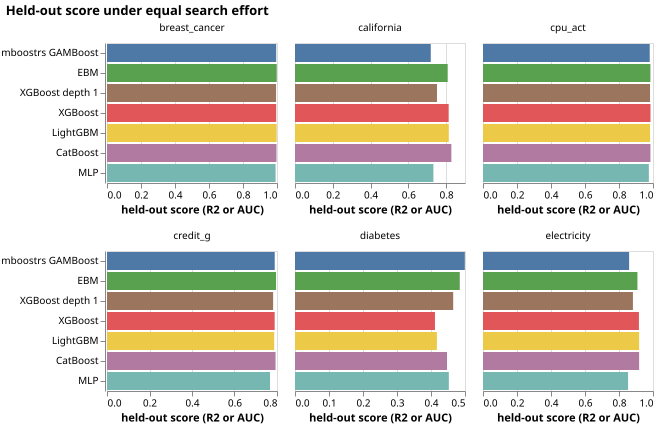

In [9]:
summary = (runs.group_by("mode", "dataset", "library", "task")
           .agg(pl.col("score").mean(), pl.col("total_seconds").mean())
           .with_columns(pl.col("library").replace_strict(
               {k: i for i, k in enumerate(ORDER)}).alias("o")))

bars = alt.Chart(summary.filter(pl.col("mode") == "configs")).mark_bar().encode(
    y=alt.Y("library:N", sort=ORDER, title=None),
    x=alt.X("score:Q", title="held-out score (R2 or AUC)",
            scale=alt.Scale(zero=False)),
    color=alt.Color("library:N", scale=scale, legend=None),
).properties(width=170, height=140).facet(
    facet=alt.Facet("dataset:N", title=None), columns=3, spacing=14
).resolve_scale(x="independent").properties(
    title="Held-out score under equal search effort"
)
bars

## Equal wall-clock time

The equal-effort protocol charges every library the same number of fits and
ignores what a fit costs. Under the second protocol each library is given
15 seconds of tuning and draws configurations until the budget is
spent, so a library that fits quickly evaluates more of its grid.

In [10]:
annotated(
    runs.filter(pl.col("mode") == "seconds")
    .group_by("library").agg(
        pl.col("configs_tried").mean().alias("configs in the budget"),
        pl.col("tune_seconds").mean().alias("tuning seconds"),
        pl.col("refit_seconds").mean().alias("refit seconds"))
    .sort("configs in the budget", descending=True),
    stub="library", stubhead="Library",
    title="What 15 seconds of tuning buys", subtitle="Mean over data sets and splits",
    labels={"configs in the budget": "configurations ↑", "tuning seconds": "tuning s",
            "refit seconds": "refit s"},
    better={"configs in the budget": "max"},
    formats={"configs in the budget": 1, "tuning seconds": 1, "refit seconds": 3},
    notes=["configurations: grid points scored by 3-fold CV within the 15-second budget. "
           "A search stops at the first configuration that ends after the budget, so "
           "tuning time can exceed 15 s. Bold: most configurations."])

GT(_tbl_data=shape: (7, 4)
┌───────────────────┬───────────────────────┬────────────────┬───────────────┐
│ library           ┆ configs in the budget ┆ tuning seconds ┆ refit seconds │
│ ---               ┆ ---                   ┆ ---            ┆ ---           │
│ str               ┆ f64                   ┆ f64            ┆ f64           │
╞═══════════════════╪═══════════════════════╪════════════════╪═══════════════╡
│ mboostrs GAMBoost ┆ 365.222222            ┆ 15.045         ┆ 0.042778      │
│ MLP               ┆ 114.666667            ┆ 15.347222      ┆ 0.165611      │
│ XGBoost depth 1   ┆ 21.611111             ┆ 15.776667      ┆ 0.329333      │
│ CatBoost          ┆ 15.277778             ┆ 16.333889      ┆ 0.828833      │
│ XGBoost           ┆ 11.0                  ┆ 16.153333      ┆ 0.400444      │
│ LightGBM          ┆ 8.5                   ┆ 17.916667      ┆ 1.094556      │
│ EBM               ┆ 3.833333              ┆ 24.476111      ┆ 6.498833      │
└───────────────────┴───────────────────────┴────────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x10fd5f3b0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='configs in the budget', type=<ColInfoTypeEnum.default: 1>, column_label='configurations ↑', column_align='right', column_width=None), ColInfo(var='tuning seconds', type=<ColInfoTypeEnum.default: 1>, column_label='tuning s', column_align='right', column_width=None), ColInfo(var='refit seconds', type=<ColInfoTypeEnum.default: 1>, column_label='refit s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fd5c8c0>, _spanners=Spanners([]), _heading=Heading(title='What 15 seconds of tuning buys', subtitle='Mean over data sets and splits', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113e1a210>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113e1a180>, _source_notes=['configurations: grid points scored by 3-fold CV within the 15-second budget. A search stops at the first configuration that ends after the budget, so tuning time can exceed 15 s. Bold: most configurations.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E1A3C0>, mask=None), grpname=None, colname='configs in the budget', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E1A3C0>, mask=None), grpname=None, colname='tuning seconds', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E1A3C0>, mask=None), grpname=None, colname='refit seconds', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x113e1a0f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x113e19fd0>, <great_tables._gt_data.FormatInfo object at 0x113e1a2d0>, <great_tables._gt_data.FormatInfo object at 0x113e1a480>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x113e1a420>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]

In [11]:
display(annotated(
    table("seconds").select("library", *DATASETS),
    stub="library", stubhead="Library",
    title="Held-out score under equal tuning time",
    subtitle="15 seconds of tuning per library; mean over 3 splits",
    spanners={"R² ↑": DATASETS[:3], "AUC ↑": DATASETS[3:]},
    better={d: "max" for d in DATASETS}, decimals=4,
    notes=[SCORE_NOTE + " Bold: best on the data set."]))
display(annotated(
    ranked("seconds"), stub="library", stubhead="Library",
    title="Mean rank and mean score, equal tuning time",
    subtitle="Rank 1 is the best library on a data set; averaged over the six",
    labels={"mean rank": "mean rank ↓", "mean score": "mean score ↑"},
    better={"mean rank": "min", "mean score": "max"}, formats={"mean rank": 2},
    decimals=4, notes=["Bold: best in the column."]))

GT(_tbl_data=shape: (7, 7)
┌───────────────────┬────────────┬─────────┬──────────┬───────────────┬──────────┬─────────────┐
│ library           ┆ california ┆ cpu_act ┆ diabetes ┆ breast_cancer ┆ credit_g ┆ electricity │
│ ---               ┆ ---        ┆ ---     ┆ ---      ┆ ---           ┆ ---      ┆ ---         │
│ str               ┆ f64        ┆ f64     ┆ f64      ┆ f64           ┆ f64      ┆ f64         │
╞═══════════════════╪════════════╪═════════╪══════════╪═══════════════╪══════════╪═════════════╡
│ mboostrs GAMBoost ┆ 0.7255     ┆ 0.9805  ┆ 0.5024   ┆ 0.9957        ┆ 0.7873   ┆ 0.8615      │
│ EBM               ┆ 0.8061     ┆ 0.9842  ┆ 0.4845   ┆ 0.9984        ┆ 0.7895   ┆ 0.902       │
│ XGBoost depth 1   ┆ 0.7515     ┆ 0.9825  ┆ 0.4598   ┆ 0.9945        ┆ 0.7818   ┆ 0.882       │
│ XGBoost           ┆ 0.8069     ┆ 0.9853  ┆ 0.4117   ┆ 0.9955        ┆ 0.7812   ┆ 0.9173      │
│ LightGBM          ┆ 0.8147     ┆ 0.9829  ┆ 0.4173   ┆ 0.998         ┆ 0.7859   ┆ 0.9188      │
│ CatBoost          ┆ 0.8278     ┆ 0.9849  ┆ 0.4602   ┆ 0.9969        ┆ 0.7928   ┆ 0.9185      │
│ MLP               ┆ 0.729      ┆ 0.9763  ┆ 0.4624   ┆ 0.9975        ┆ 0.7629   ┆ 0.8474      │
└───────────────────┴────────────┴─────────┴──────────┴───────────────┴──────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10fd5ce90>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='california', type=<ColInfoTypeEnum.default: 1>, column_label='california', column_align='right', column_width=None), ColInfo(var='cpu_act', type=<ColInfoTypeEnum.default: 1>, column_label='cpu_act', column_align='right', column_width=None), ColInfo(var='diabetes', type=<ColInfoTypeEnum.default: 1>, column_label='diabetes', column_align='right', column_width=None), ColInfo(var='breast_cancer', type=<ColInfoTypeEnum.default: 1>, column_label='breast_cancer', column_align='right', column_width=None), ColInfo(var='credit_g', type=<ColInfoTypeEnum.default: 1>, column_label='credit_g', column_align='right', column_width=None), ColInfo(var='electricity', type=<ColInfoTypeEnum.default: 1>, column_label='electricity', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fd5f860>, _spanners=Spanners([SpannerInfo(spanner_id='R² ↑', spanner_level=0, spanner_label='R² ↑', spanner_units=None, spanner_pattern=None, vars=['california', 'cpu_act', 'diabetes'], built=None), SpannerInfo(spanner_id='AUC ↑', spanner_level=0, spanner_label='AUC ↑', spanner_units=None, spanner_pattern=None, vars=['breast_cancer', 'credit_g', 'electricity'], built=None)]), _heading=Heading(title='Held-out score under equal tuning time', subtitle='15 seconds of tuning per library; mean over 3 splits', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113e1bb30>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113e411c0>, _source_notes=['Scores are the mean over three random 75/25 splits shared by every library: test R² for california, cpu_act and diabetes, test ROC AUC for breast_cancer, credit_g and electricity; both are higher-is-better with 1 the maximum. Bold: best on the data set.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E41580>, mask=None), grpname=None, colname='california', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E41580>, mask=None), grpname=None, colname='cpu_act', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E41580>, mask=None), grpname=None, colname='diabetes', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Exp

GT(_tbl_data=shape: (7, 3)
┌───────────────────┬───────────┬────────────┐
│ library           ┆ mean rank ┆ mean score │
│ ---               ┆ ---       ┆ ---        │
│ str               ┆ f64       ┆ f64        │
╞═══════════════════╪═══════════╪════════════╡
│ CatBoost          ┆ 2.33      ┆ 0.8302     │
│ EBM               ┆ 2.67      ┆ 0.8275     │
│ LightGBM          ┆ 3.17      ┆ 0.8196     │
│ XGBoost           ┆ 4.33      ┆ 0.8163     │
│ mboostrs GAMBoost ┆ 4.67      ┆ 0.8088     │
│ XGBoost depth 1   ┆ 5.33      ┆ 0.8087     │
│ MLP               ┆ 5.5       ┆ 0.7959     │
└───────────────────┴───────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10fd8d550>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='mean rank', type=<ColInfoTypeEnum.default: 1>, column_label='mean rank ↓', column_align='right', column_width=None), ColInfo(var='mean score', type=<ColInfoTypeEnum.default: 1>, column_label='mean score ↑', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fd8c1d0>, _spanners=Spanners([]), _heading=Heading(title='Mean rank and mean score, equal tuning time', subtitle='Rank 1 is the best library on a data set; averaged over the six', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fd5c620>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fd5fd40>, _source_notes=['Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E425A0>, mask=None), grpname=None, colname='mean rank', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E425A0>, mask=None), grpname=None, colname='mean score', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10fd5ca40>, _formats=[<great_tables._gt_data.FormatInfo object at 0x113e41490>, <great_tables._gt_data.FormatInfo object at 0x113e40f20>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x113e40f80>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top

In 15 seconds mboostrs evaluates 365 configurations and EBM evaluates 4 — a
factor of 95. The ranking barely moves. mboostrs stays at 4.67, exactly where it
was under equal search effort, and no library's mean score moves by more than
0.003.

The additional search produces little score improvement within these grids.
This suggests that twelve configurations already reached useful settings for
these datasets. Changing tuning effort alone does not change whether the
specified learner can represent interactions.

In [12]:
shift = (runs.group_by("mode", "library").agg(pl.col("score").mean())
         .pivot(on="mode", index="library", values="score")
         .with_columns((pl.col("seconds") - pl.col("configs")).alias("change"))
         .with_columns(pl.col("configs", "seconds", "change").round(4))
         .sort("change"))
display(annotated(
    shift, stub="library", stubhead="Library", decimals=4,
    title="Change in mean score from equal effort to equal time",
    subtitle="Mean held-out score over data sets and splits",
    labels={"configs": "equal effort", "seconds": "equal time", "change": "change"},
    notes=["change: equal time minus equal effort; positive when more search helped."]))

GT(_tbl_data=shape: (7, 4)
┌───────────────────┬─────────┬─────────┬─────────┐
│ library           ┆ seconds ┆ configs ┆ change  │
│ ---               ┆ ---     ┆ ---     ┆ ---     │
│ str               ┆ f64     ┆ f64     ┆ f64     │
╞═══════════════════╪═════════╪═════════╪═════════╡
│ EBM               ┆ 0.8275  ┆ 0.83    ┆ -0.0026 │
│ XGBoost           ┆ 0.8163  ┆ 0.8187  ┆ -0.0024 │
│ XGBoost depth 1   ┆ 0.8087  ┆ 0.8096  ┆ -0.0009 │
│ LightGBM          ┆ 0.8196  ┆ 0.8196  ┆ 0.0     │
│ MLP               ┆ 0.7959  ┆ 0.7955  ┆ 0.0004  │
│ mboostrs GAMBoost ┆ 0.8088  ┆ 0.8072  ┆ 0.0016  │
│ CatBoost          ┆ 0.8302  ┆ 0.8281  ┆ 0.0021  │
└───────────────────┴─────────┴─────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x113e1a450>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='equal time', column_align='right', column_width=None), ColInfo(var='configs', type=<ColInfoTypeEnum.default: 1>, column_label='equal effort', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='change', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fd5c620>, _spanners=Spanners([]), _heading=Heading(title='Change in mean score from equal effort to equal time', subtitle='Mean held-out score over data sets and splits', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113e1a510>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113e1abd0>, _source_notes=['change: equal time minus equal effort; positive when more search helped.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E404D0>, mask=None), grpname=None, colname='seconds', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E404D0>, mask=None), grpname=None, colname='configs', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E404D0>, mask=None), grpname=None, colname='change', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x113e40080>, _formats=[<great_tables._gt_data.FormatInfo object at 0x113e40920>, <great_tables._gt_data.FormatInfo object at 0x113e40380>, <great_tables._gt_data.FormatInfo object at 0x113e414c0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x113e419a0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal

## Accuracy and computing time

`total_seconds` is everything a run spent: the whole tuning search plus the
final refit. It is the number a practitioner pays per dataset.

In [13]:
annotated(
    runs.filter(pl.col("mode") == "configs")
    .group_by("library").agg(
        pl.col("total_seconds").mean().alias("seconds to tune and refit"),
        pl.col("refit_seconds").mean().alias("seconds for the final refit"))
    .sort("seconds to tune and refit"),
    stub="library", stubhead="Library",
    title="Computing time under equal search effort",
    subtitle="Mean over data sets and splits",
    labels={"seconds to tune and refit": "tune and refit, s ↓",
            "seconds for the final refit": "final refit, s ↓"},
    better={"seconds to tune and refit": "min", "seconds for the final refit": "min"},
    formats={"seconds to tune and refit": 1, "seconds for the final refit": 3},
    notes=["tune and refit: the whole 12-configuration search plus the final refit. "
           "Bold: fastest."])

GT(_tbl_data=shape: (7, 3)
┌───────────────────┬───────────────────────────┬─────────────────────────────┐
│ library           ┆ seconds to tune and refit ┆ seconds for the final refit │
│ ---               ┆ ---                       ┆ ---                         │
│ str               ┆ f64                       ┆ f64                         │
╞═══════════════════╪═══════════════════════════╪═════════════════════════════╡
│ mboostrs GAMBoost ┆ 1.002778                  ┆ 0.034                       │
│ MLP               ┆ 6.337778                  ┆ 0.161889                    │
│ XGBoost depth 1   ┆ 8.649444                  ┆ 0.372333                    │
│ CatBoost          ┆ 14.808889                 ┆ 0.676944                    │
│ XGBoost           ┆ 19.602778                 ┆ 0.421778                    │
│ LightGBM          ┆ 37.095                    ┆ 1.057444                    │
│ EBM               ┆ 105.154444                ┆ 6.179167                    │
└───────────────────┴───────────────────────────┴─────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x113e41520>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='seconds to tune and refit', type=<ColInfoTypeEnum.default: 1>, column_label='tune and refit, s ↓', column_align='right', column_width=None), ColInfo(var='seconds for the final refit', type=<ColInfoTypeEnum.default: 1>, column_label='final refit, s ↓', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x113e1bef0>, _spanners=Spanners([]), _heading=Heading(title='Computing time under equal search effort', subtitle='Mean over data sets and splits', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113e41550>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113e41220>, _source_notes=['tune and refit: the whole 12-configuration search plus the final refit. Bold: fastest.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E40F20>, mask=None), grpname=None, colname='seconds to tune and refit', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x113E40F20>, mask=None), grpname=None, colname='seconds for the final refit', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x113e40ce0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x113e41280>, <great_tables._gt_data.FormatInfo object at 0x113e40fb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x113e41a60>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True

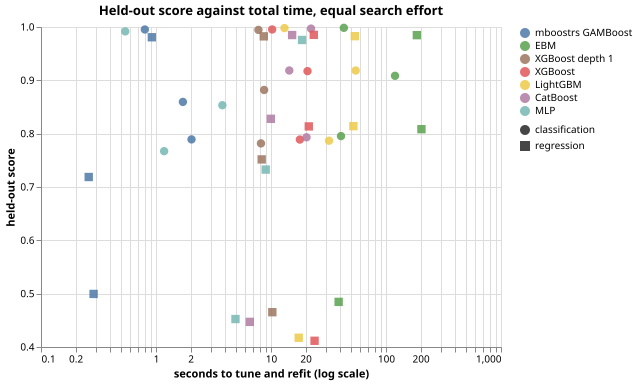

In [14]:
cost = summary.filter(pl.col("mode") == "configs")
points = alt.Chart(cost).mark_point(size=70, filled=True, opacity=0.85).encode(
    x=alt.X("total_seconds:Q", title="seconds to tune and refit (log scale)",
            scale=alt.Scale(type="log")),
    y=alt.Y("score:Q", title="held-out score", scale=alt.Scale(zero=False)),
    color=alt.Color("library:N", scale=scale, title=None),
    shape=alt.Shape("task:N", title=None),
    tooltip=["library", "dataset", "score", "total_seconds"],
)
points.properties(width=460, height=320,
                  title="Held-out score against total time, equal search effort")

mboostrs tunes and refits in 1.0 seconds on average against EBM's 105.2, a
factor of 105, and it is the fastest of the seven by a factor of 6 over the next
one. The two additive models sit at opposite ends of the cost axis while
finishing level on accuracy: EBM is the most expensive model in the comparison
and mboostrs the cheapest.

The chart compares held-out score with tuning and refitting time. Points at
the same height have similar scores; their horizontal separation shows the
difference in elapsed computation time.

## Additive models compared

`mboostrs GAMBoost` and `XGBoost depth 1` both fit sums of one-dimensional
terms, using smooth curves and stumps respectively. Their comparison retains
additivity while changing the learner and library. Comparisons with deeper
trees also change interaction capacity, so their score gaps cannot be
attributed to interactions alone.

In [15]:
additive = ["mboostrs GAMBoost", "XGBoost depth 1"]
full = ["XGBoost", "LightGBM", "CatBoost"]
contrast = (runs.filter(pl.col("mode") == "configs")
            .group_by("dataset", "library").agg(pl.col("score").mean())
            .group_by("dataset").agg(
                pl.col("score").filter(pl.col("library") == "mboostrs GAMBoost")
                  .first().alias("mboostrs"),
                pl.col("score").filter(pl.col("library") == "XGBoost depth 1")
                  .first().alias("XGBoost depth 1"),
                pl.col("score").filter(pl.col("library").is_in(full))
                  .max().alias("best unrestricted"))
            .with_columns(
                (pl.col("mboostrs") - pl.col("XGBoost depth 1")).alias("library gap"),
                (pl.col("best unrestricted") - pl.col("mboostrs")).alias("interaction gap"))
            .with_columns(pl.exclude("dataset").round(4))
            .sort("interaction gap", descending=True))
display(annotated(
    contrast, stub="dataset", stubhead="Data set", decimals=4,
    title="Additive models against the best unrestricted model",
    subtitle="Mean held-out score over 3 splits, equal search effort",
    notes=[SCORE_NOTE, "library gap: mboostrs minus XGBoost depth 1, the same function "
           "class. interaction gap: the best of XGBoost, LightGBM and CatBoost minus "
           "mboostrs, what fitting interactions is worth on the data set."]))

GT(_tbl_data=shape: (6, 6)
┌───────────────┬──────────┬─────────────────┬───────────────────┬─────────────┬─────────────────┐
│ dataset       ┆ mboostrs ┆ XGBoost depth 1 ┆ best unrestricted ┆ library gap ┆ interaction gap │
│ ---           ┆ ---      ┆ ---             ┆ ---               ┆ ---         ┆ ---             │
│ str           ┆ f64      ┆ f64             ┆ f64               ┆ f64         ┆ f64             │
╞═══════════════╪══════════╪═════════════════╪═══════════════════╪═════════════╪═════════════════╡
│ california    ┆ 0.7187   ┆ 0.7517          ┆ 0.8278            ┆ -0.033      ┆ 0.1091          │
│ electricity   ┆ 0.8595   ┆ 0.8819          ┆ 0.9185            ┆ -0.0224     ┆ 0.0589          │
│ cpu_act       ┆ 0.9808   ┆ 0.9825          ┆ 0.9853            ┆ -0.0017     ┆ 0.0045          │
│ credit_g      ┆ 0.7893   ┆ 0.7818          ┆ 0.7932            ┆ 0.0075      ┆ 0.0039          │
│ breast_cancer ┆ 0.9953   ┆ 0.9945          ┆ 0.998             ┆ 0.0008      ┆ 0.0027          │
│ diabetes      ┆ 0.4995   ┆ 0.4653          ┆ 0.4471            ┆ 0.0342      ┆ -0.0524         │
└───────────────┴──────────┴─────────────────┴───────────────────┴─────────────┴─────────────────┘, _body=<great_tables._gt_data.Body object at 0x10e1f73b0>, _boxhead=Boxhead([ColInfo(var='dataset', type=<ColInfoTypeEnum.stub: 2>, column_label='dataset', column_align='left', column_width=None), ColInfo(var='mboostrs', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs', column_align='right', column_width=None), ColInfo(var='XGBoost depth 1', type=<ColInfoTypeEnum.default: 1>, column_label='XGBoost depth 1', column_align='right', column_width=None), ColInfo(var='best unrestricted', type=<ColInfoTypeEnum.default: 1>, column_label='best unrestricted', column_align='right', column_width=None), ColInfo(var='library gap', type=<ColInfoTypeEnum.default: 1>, column_label='library gap', column_align='right', column_width=None), ColInfo(var='interaction gap', type=<ColInfoTypeEnum.default: 1>, column_label='interaction gap', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x113e1a930>, _spanners=Spanners([]), _heading=Heading(title='Additive models against the best unrestricted model', subtitle='Mean held-out score over 3 splits, equal search effort', preheader=None), _stubhead='Data set', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113e429f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113e426f0>, _source_notes=['Scores are the mean over three random 75/25 splits shared by every library: test R² for california, cpu_act and diabetes, test ROC AUC for breast_cancer, credit_g and electricity; both are higher-is-better with 1 the maximum.', 'library gap: mboostrs minus XGBoost depth 1, the same function class. interaction gap: the best of XGBoost, LightGBM and CatBoost minus mboostrs, what fitting interactions is worth on the data set.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x113e42570>, _formats=[<great_tables._gt_data.FormatInfo object at 0x113e1a960>, <great_tables._gt_data.FormatInfo object at 0x113e41d90>, <great_tables._gt_data.FormatInfo object at 0x113e418e0>, <great_tables._gt_data.FormatInfo object at 0x113e40980>, <great_tables._gt_data.FormatInfo object at 0x113e40cb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x113e426c0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsIn

The interaction gap is the improvement from being allowed to fit interactions:
the best unrestricted model minus mboostrs. On four of the six datasets it is
under 0.008, which is inside the noise of three splits. On diabetes it is
negative — the additive fit is the best of all seven, and the unrestricted
models overfit 331 training rows.

Two datasets carry the whole difference. On california it is 0.109 and on
electricity 0.059. California housing is priced by geography, and geography
enters through latitude interacting with longitude; that is the case additivity
cannot express, and no tuning budget substitutes for it.

The library gap is mboostrs minus depth-1 XGBoost, both additive. It is under
0.01 in absolute value on three datasets and favours mboostrs on three. It is −0.033 on
california and −0.022 on electricity, where depth-1 XGBoost is ahead, and +0.034 on
diabetes, where mboostrs is ahead. Both models fit sums of one-dimensional terms,
so these gaps are not about interactions. On california a `df=4` P-spline smooths a
sharp geographic threshold that a thousand stumps reproduce; this is one explanation
and the benchmark does not test it. Additivity is one constraint; smoothness is a
second, and california penalises both.

## Check: learners for indicator columns

The sklearn wrapper gives every column a `bbs` smooth term. Four of the six
datasets are entirely numeric, but credit_g is 59 columns of which 53 are
one-hot indicators, and a P-spline on a two-valued column is a strange object.
If that were costing mboostrs accuracy, its credit_g result would be an artefact
of the encoding rather than a property of the model.

It is not. Replacing the spline with a linear term on every two-valued column
leaves held-out AUC at 0.8239.

In [16]:
import sys

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from mboostrs.sklearn import GAMBoostClassifier

sys.path.insert(0, str(Path("../../../benches").resolve()))
import bench_libraries as bench

task, Xc, yc = bench.encoded_datasets()["credit_g"]
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, random_state=0,
                                      stratify=yc)
levels = np.array([len(np.unique(Xc[:, j])) for j in range(Xc.shape[1])])
print(f"credit_g: {int((levels <= 2).sum())} two-valued columns, "
      f"{int((levels > 2).sum())} continuous")

default = GAMBoostClassifier(mstop=400, nu=0.1, df=4).fit(Xtr, ytr)
rhs = " + ".join(f"bols(f{j})" if levels[j] <= 2 else f"bbs(f{j}, df=4)"
                 for j in range(Xc.shape[1]))
tailored = GAMBoostClassifier(formula="y ~ " + rhs, mstop=400, nu=0.1).fit(Xtr, ytr)
for label, fitted in (("bbs on every column", default),
                      ("bols on the indicators", tailored)):
    print(f"  {label:24s} AUC "
          f"{roc_auc_score(yte, fitted.predict_proba(Xte)[:, 1]):.4f}")

credit_g: 53 two-valued columns, 6 continuous


  bbs on every column      AUC 0.8239
  bols on the indicators   AUC 0.8239


## Summary

The Kumo extension adds a fixed pretrained small model on the same outer splits.
Its eight-model accuracy comparison and per-split variation are reported separately
from the seven-model tuning analysis. Kumo inference time excludes upstream
pretraining, and its weight loading is reported separately.

The tables above report held-out scores under equal configuration counts and equal tuning time. The depth-one XGBoost control and `GAMBoost` are both additive, while the deeper tree models can represent interactions. `GAMBoost` is fastest in this recorded search; its accuracy varies by dataset, so the mean rank does not describe every task. Tuning and final-refit times are reported separately.

## Limitations

Six datasets capped at 5000 rows and three splits each. That is enough to
separate 0.1 on california and not enough to separate 0.007 on breast_cancer,
and no ranking here should be read as separating libraries that finish within a
few thousandths of each other.

Twelve configurations from a hand-written grid per library. The grids were
matched for generosity — a rate, a capacity knob and a regularisation knob each
— but they are not the tuned pipelines any of these libraries would get in a
competition, and a library whose useful region sits outside its grid here would
be understated.

The datasets are all small-to-medium and dense. Nothing here says anything about
behaviour at a million rows, about wide sparse data, or about native categorical
handling, which was deliberately removed by one-hot encoding everything so that
the comparison would not turn into a test of six different categorical encoders.

Accuracy is the only thing scored. mboostrs and EBM report fitted effects
by term, while the unrestricted models do not. The held-out scores do not
determine whether that interpretability difference justifies a gap of 0.1
on california or 0.007 on breast_cancer.